In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv('01_cleaned_hr_data.csv')


df['target_accepted'] = (df['status'] == 'Placed').astype(int)


df['experience_category'] = pd.cut(
    df['years_of_experience'],
    bins=[-1, 0, 2, 10],
    labels=['Fresher', 'Junior', 'Senior']
)


df['avg_academic_score'] = df[['ssc_percentage', 'hsc_percentage', 'degree_percentage']].mean(axis=1)
df['academic_band'] = pd.cut(
    df['avg_academic_score'],
    bins=[0, 65, 75, 100],
    labels=['Average', 'Good', 'Distinction']
)


df['skills_match_level'] = pd.cut(
    df['skills_match_percentage'],
    bins=[0, 60, 80, 100],
    labels=['Low', 'Medium', 'High']
)


df['avg_interview_score'] = df[['technical_score', 'aptitude_score', 'communication_score']].mean(axis=1)
df['interview_performance'] = pd.cut(
    df['avg_interview_score'],
    bins=[0, 60, 75, 100],
    labels=['Needs Improvement', 'Moderate', 'Strong']
)


df['ctc_hike_ratio'] = (df['expected_ctc_lpa'] - df['previous_ctc_lpa']) / df['previous_ctc_lpa']


df['high_risk_flag'] = np.where(
    (df['ctc_hike_ratio'] > 0.60) | (df['notice_period_days'] >= 60) | (df['job_role_match'] == 'Not Matched'),
    'High Risk',
    'Low Risk'
)

print("Engineered features added! New shape:", df.shape)
display(df[['experience_category', 'academic_band', 'skills_match_level', 'interview_performance', 'ctc_hike_ratio', 'high_risk_flag']].head())


Engineered features added! New shape: (50000, 35)


,experience_category,academic_band,skills_match_level,interview_performance,ctc_hike_ratio,high_risk_flag
0,Junior,Good,Medium,Moderate,0.644457,High Risk
1,Fresher,Good,Medium,Moderate,0.096325,Low Risk
2,Junior,Distinction,Medium,Moderate,-0.056013,High Risk
3,Fresher,Distinction,Medium,Moderate,3.686147,High Risk
4,Fresher,Good,High,Moderate,0.122406,Low Risk


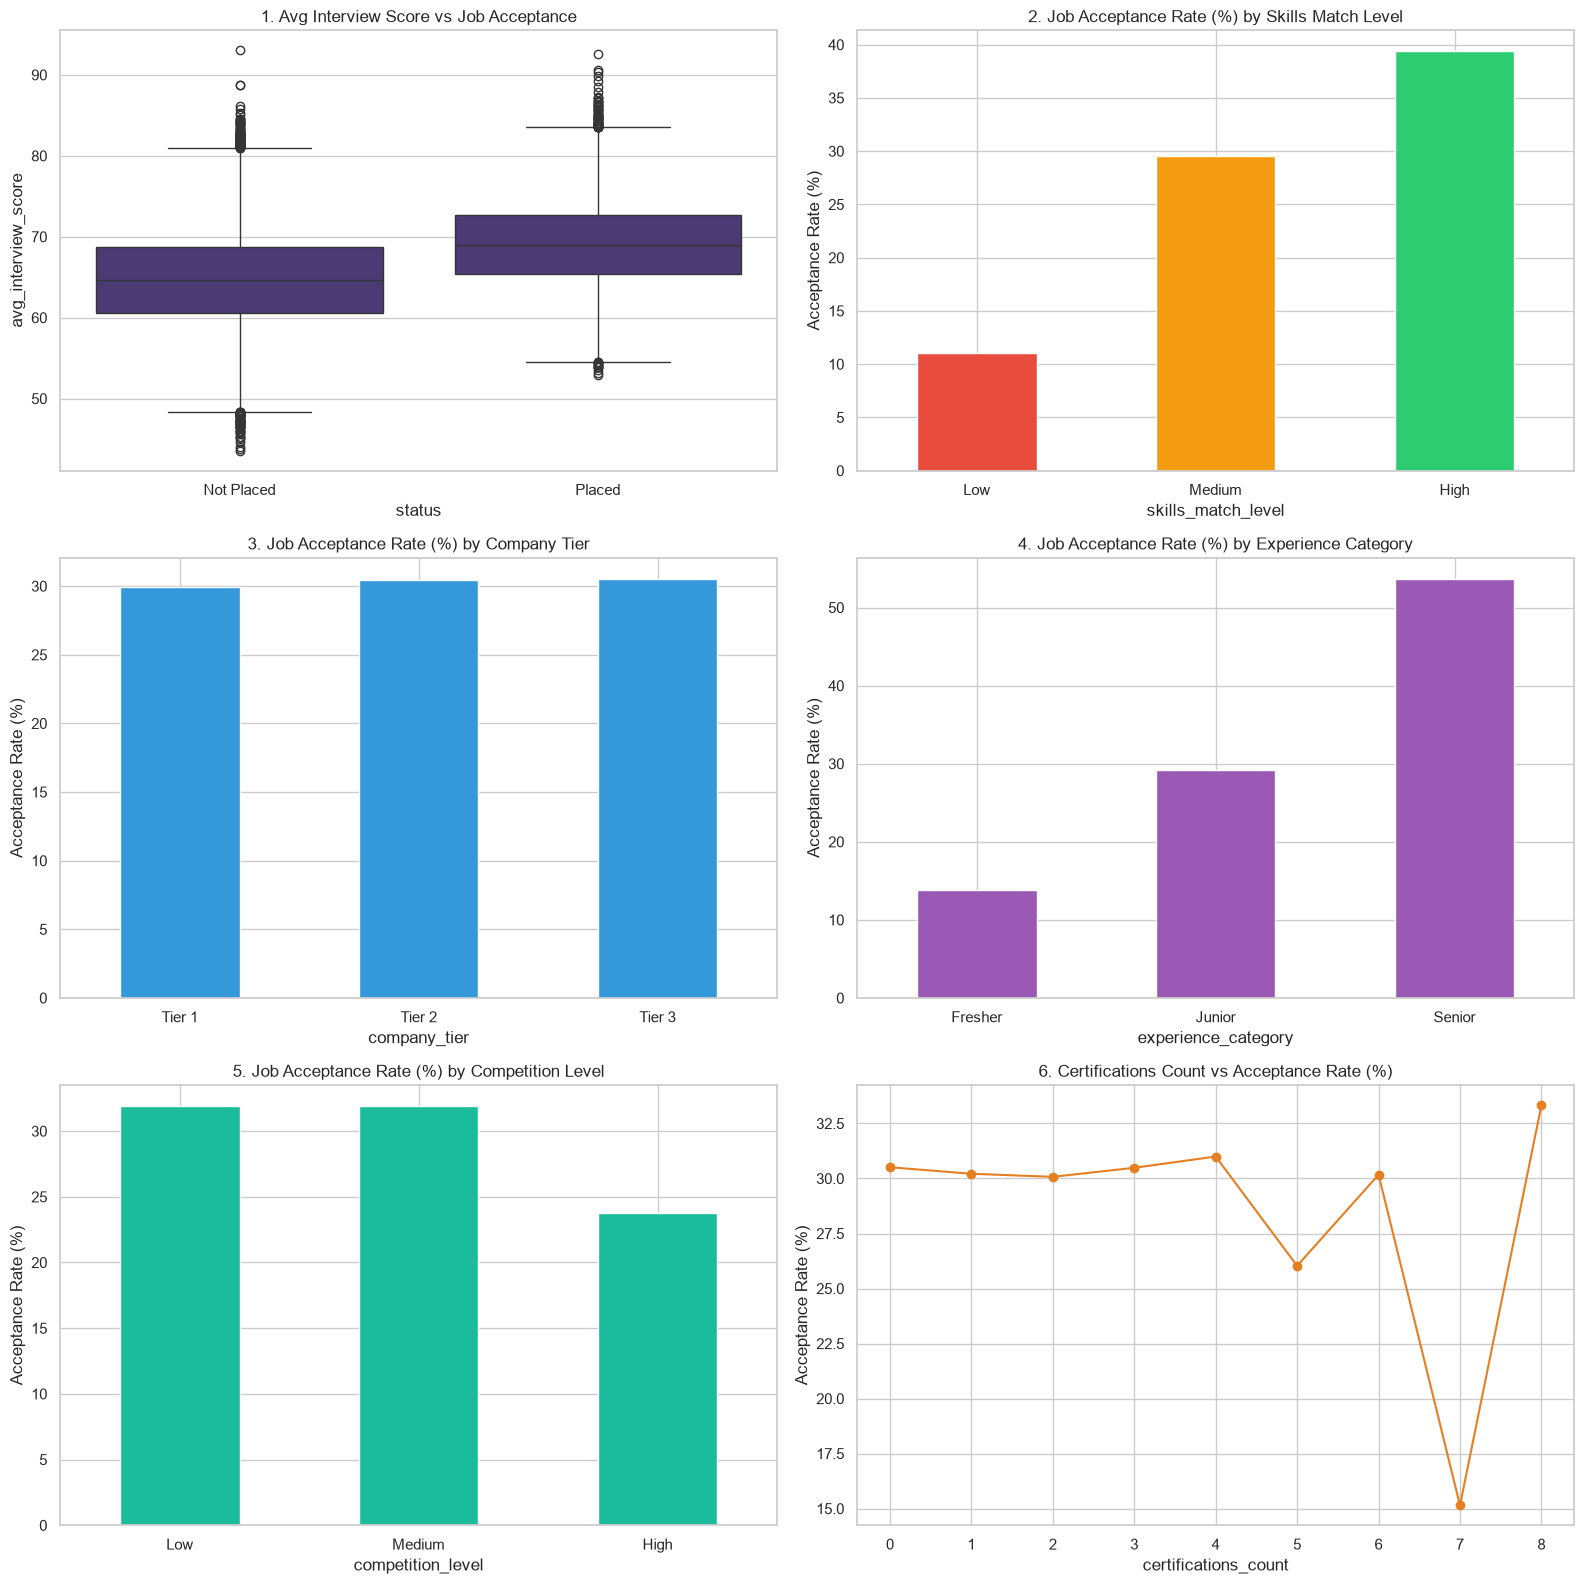

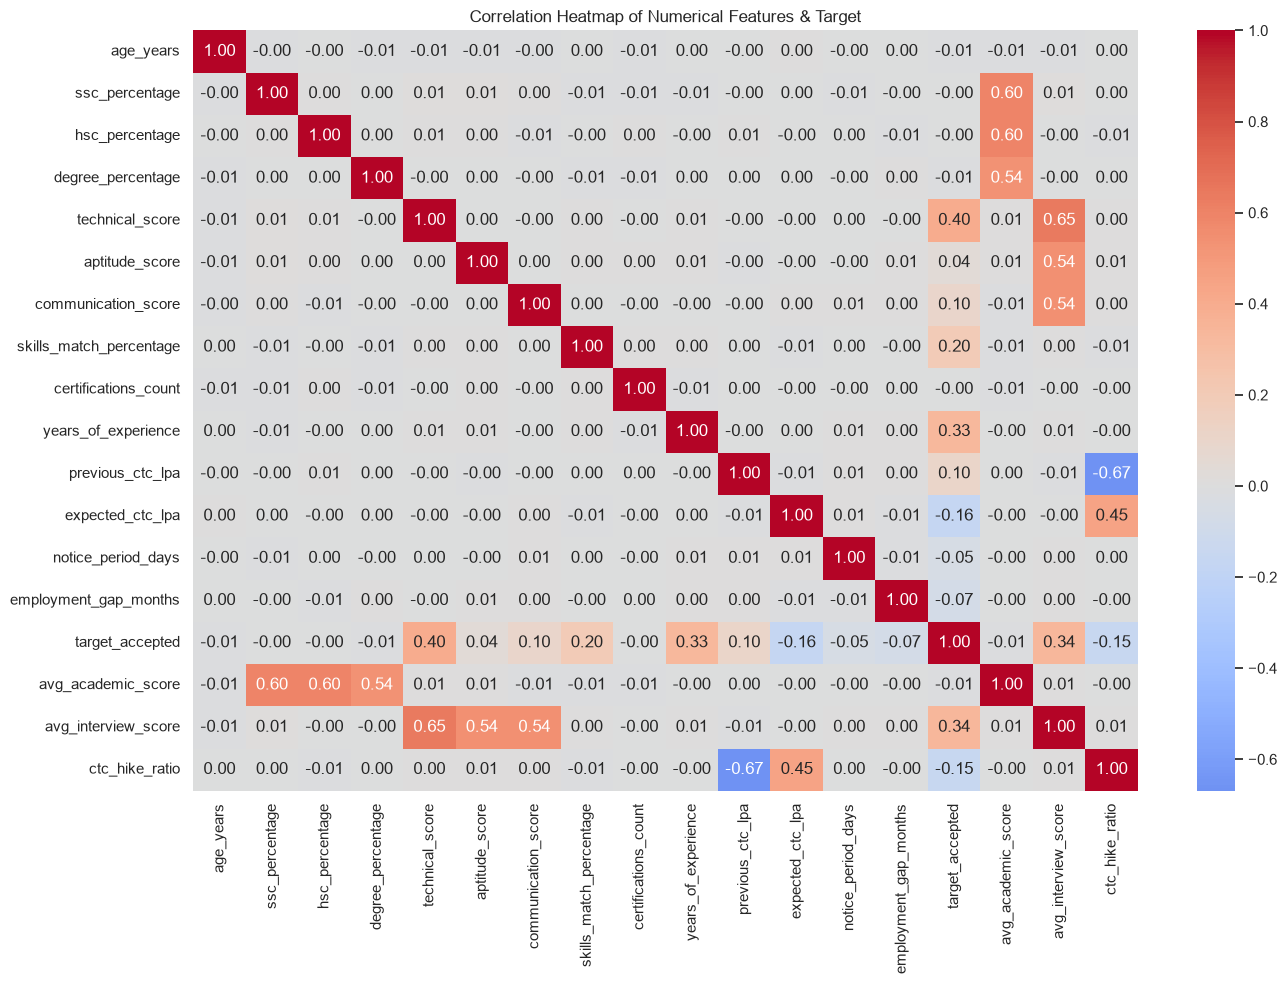

Saved feature-engineered dataset to '02_featured_hr_data.csv'!


In [2]:
sns.set_theme(style="whitegrid", palette="viridis")
fig, axes = plt.subplots(3, 2, figsize=(16, 16))

# 1. Interview Score vs Job Acceptance
sns.boxplot(data=df, x='status', y='avg_interview_score', ax=axes[0, 0])
axes[0, 0].set_title('1. Avg Interview Score vs Job Acceptance')

# 2. Skills Match Level vs Acceptance Rate
skills_rate = df.groupby('skills_match_level', observed=False)['target_accepted'].mean() * 100
skills_rate.plot(kind='bar', ax=axes[0, 1], color=['#e74c3c', '#f39c12', '#2ecc71'])
axes[0, 1].set_title('2. Job Acceptance Rate (%) by Skills Match Level')
axes[0, 1].set_ylabel('Acceptance Rate (%)')
axes[0, 1].tick_params(axis='x', rotation=0)

# 3. Company Tier vs Acceptance Rate
tier_rate = df.groupby('company_tier')['target_accepted'].mean() * 100
tier_rate.plot(kind='bar', ax=axes[1, 0], color='#3498db')
axes[1, 0].set_title('3. Job Acceptance Rate (%) by Company Tier')
axes[1, 0].set_ylabel('Acceptance Rate (%)')
axes[1, 0].tick_params(axis='x', rotation=0)

# 4. Experience Category vs Placement Success
exp_rate = df.groupby('experience_category', observed=False)['target_accepted'].mean() * 100
exp_rate.plot(kind='bar', ax=axes[1, 1], color='#9b59b6')
axes[1, 1].set_title('4. Job Acceptance Rate (%) by Experience Category')
axes[1, 1].set_ylabel('Acceptance Rate (%)')
axes[1, 1].tick_params(axis='x', rotation=0)

# 5. Competition Level vs Job Acceptance
comp_rate = df.groupby('competition_level')['target_accepted'].mean() * 100
comp_rate.loc[['Low', 'Medium', 'High']].plot(kind='bar', ax=axes[2, 0], color='#1abc9c')
axes[2, 0].set_title('5. Job Acceptance Rate (%) by Competition Level')
axes[2, 0].set_ylabel('Acceptance Rate (%)')
axes[2, 0].tick_params(axis='x', rotation=0)

# 6. Certifications Count vs Acceptance Rate
cert_rate = df.groupby('certifications_count')['target_accepted'].mean() * 100
cert_rate.plot(kind='line', marker='o', ax=axes[2, 1], color='#e67e22')
axes[2, 1].set_title('6. Certifications Count vs Acceptance Rate (%)')
axes[2, 1].set_ylabel('Acceptance Rate (%)')

plt.tight_layout()
plt.show()

# 7. Correlation Heatmap among Numerical Features
plt.figure(figsize=(14, 10))
num_df = df.select_dtypes(include=[np.number])
sns.heatmap(num_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Numerical Features & Target')
plt.tight_layout()
plt.show()

# Save feature-engineered dataset for SQL & ML Modeling
df.to_csv('02_featured_hr_data.csv', index=False)
print("Saved feature-engineered dataset to '02_featured_hr_data.csv'!")
